In [16]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import contextily
from pathlib import Path

vis_dir = Path("../visualizations")

In [17]:
berk = gpd.read_parquet("../data/processed/berk_parcels_acs.parquet")

berk["acres_geom"] = berk.geometry.area / 43560   # CRS is in US feet, 43,560 sq ft per acre

berk["pop_other"] = berk["pop_total"] - berk["pop_nh_white"] - berk["pop_nh_black"] - berk["pop_nh_asian"] - berk["pop_hispanic"]
berk["pop_other"] = berk["pop_other"].clip(lower=0)

berk["pct_nonwhite"] = 100 - berk["pct_nh_white"]

race_groups = ["White", "Asian", "Hispanic/Latino", "Black", "Other"]
print(len(berk), "parcels")

9318 parcels


In [18]:
cols = ["GEOID", "pop_total", "pop_nh_white", "pop_nh_asian", "pop_hispanic", "pop_nh_black", "pop_other"]
bg = berk[cols].dropna(subset=["GEOID"]).drop_duplicates("GEOID").set_index("GEOID")
bg = bg.rename(columns={"pop_nh_white": "White", "pop_nh_asian": "Asian", "pop_hispanic": "Hispanic/Latino",
                        "pop_nh_black": "Black", "pop_other": "Other"})

shares = bg[race_groups].div(bg["pop_total"], axis=0).fillna(0)

# find the largest group by checking each one
bg["largest_group"] = "No data"
bg["largest_share"] = 0.0
for grp in race_groups:
    bigger = shares[grp] > bg["largest_share"]
    bg.loc[bigger, "largest_group"] = grp
    bg.loc[bigger, "largest_share"] = shares[grp]

bg["is_majority"] = bg["largest_share"] > 0.5

# attach the result back onto the parcels
berk = berk.merge(bg[["largest_group", "largest_share", "is_majority"]], left_on="GEOID", right_index=True, how="left")
berk["largest_group"] = berk["largest_group"].fillna("No data")

print(len(bg), "block groups,", round(bg["is_majority"].mean() * 100), "% have a true majority group")
bg.groupby(["largest_group", "is_majority"]).size().unstack(fill_value=0)

63 block groups, 49 % have a true majority group


is_majority,False,True
largest_group,,
Asian,10,5
Hispanic/Latino,1,0
White,21,26


In [19]:
colors = {
    "White":           "#2a78d6",
    "Asian":           "#eb6834",
    "Hispanic/Latino": "#1baf7a",
    "Black":           "#5b2a86",
    "Other":           "#8a8986",
}
no_data_color = "#d9d9d6"
LIGHT = 0.4

nonwhite_bins   = [0, 20, 40, 60, 80, 100]
nonwhite_labels = ["0–20%", "20–40%", "40–60%", "60–80%", "80–100%"]
nonwhite_colors = ["#fde0ef", "#f4a9cb", "#e0679c", "#b0306b", "#6e0d40"]

SCALE_COLORS = {0: "#A9A9A9", 1: "#f0f921", 2: "#fdb42f", 3: "#ed7953", 4: "#cc4778"}   # same as Eve's map

def add_basemap(ax):
    try:
        contextily.add_basemap(ax, crs=berk.crs, source=contextily.providers.Esri.WorldGrayCanvas)
    except Exception:
        print("basemap could not load (no internet?) - map drawn without it")

/opt/anaconda3/lib/python3.14/site-packages/geopandas/plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


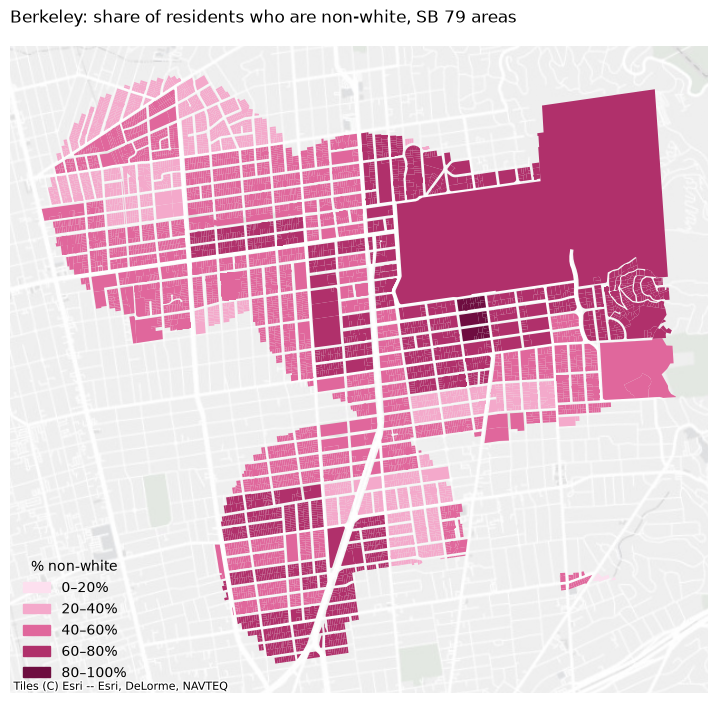

In [20]:
berk["nw_bin"] = pd.cut(berk["pct_nonwhite"], bins=nonwhite_bins, labels=nonwhite_labels, include_lowest=True)

def plot_nonwhite(ax, title):
    # one layer per bin, so each bin gets its own color
    for label, color in zip(nonwhite_labels, nonwhite_colors):
        berk[berk["nw_bin"] == label].plot(ax=ax, color=color, linewidth=0)
    berk[berk["nw_bin"].isna()].plot(ax=ax, color=no_data_color, linewidth=0)
    add_basemap(ax)

    handles = []
    for label, color in zip(nonwhite_labels, nonwhite_colors):
        handles.append(Patch(color=color, label=label))
    ax.legend(handles=handles, title="% non-white", loc="lower left", frameon=False)
    ax.set_title(title, loc="left")
    ax.set_axis_off()

fig, ax = plt.subplots(figsize=(9, 9))
plot_nonwhite(ax, "Berkeley: share of residents who are non-white, SB 79 areas")
plt.savefig(vis_dir / "berk_pct_nonwhite_map.png", dpi=150, bbox_inches="tight")
plt.show()

/opt/anaconda3/lib/python3.14/site-packages/geopandas/plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


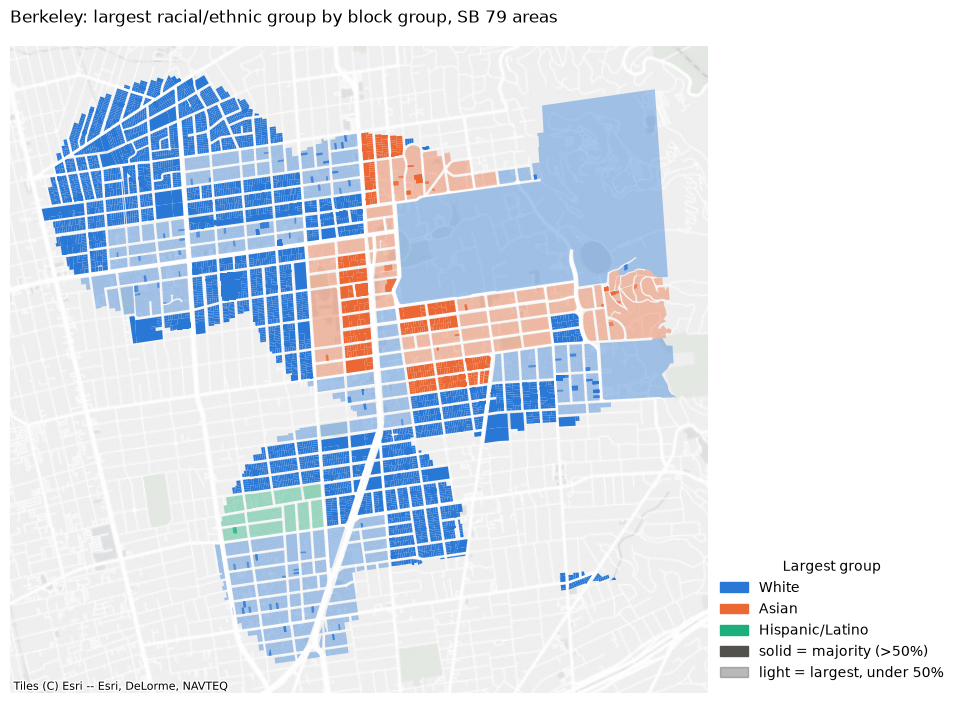

In [21]:
fig, ax = plt.subplots(figsize=(9, 9))

handles = []
for grp in race_groups:
    majority  = berk[(berk["largest_group"] == grp) & (berk["is_majority"] == True)]
    plurality = berk[(berk["largest_group"] == grp) & (berk["is_majority"] == False)]
    if len(majority) > 0:
        majority.plot(ax=ax, color=colors[grp], linewidth=0)
    if len(plurality) > 0:
        plurality.plot(ax=ax, color=colors[grp], alpha=LIGHT, linewidth=0)
    if len(majority) + len(plurality) > 0:
        handles.append(Patch(color=colors[grp], label=grp))
berk[berk["largest_group"] == "No data"].plot(ax=ax, color=no_data_color, linewidth=0)
add_basemap(ax)

handles.append(Patch(color="#52514e", label="solid = majority (>50%)"))
handles.append(Patch(color="#52514e", alpha=LIGHT, label="light = largest, under 50%"))
ax.legend(handles=handles, title="Largest group", loc="lower left", bbox_to_anchor=(1, 0), frameon=False)
ax.set_title("Berkeley: largest racial/ethnic group by block group, SB 79 areas", loc="left")
ax.set_axis_off()
plt.savefig(vis_dir / "berk_majority_race_map.png", dpi=150, bbox_inches="tight")
plt.show()

/opt/anaconda3/lib/python3.14/site-packages/geopandas/plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


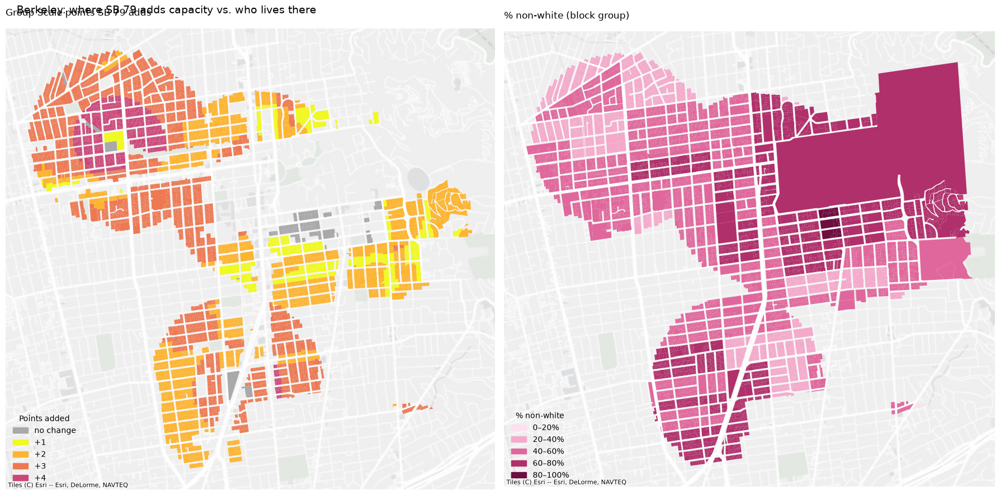

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(18, 9))

# left: Eve's points-added map
handles = []
for pts, color in SCALE_COLORS.items():
    layer = berk[berk['net_scale_increase'] == pts]
    if len(layer) > 0:
        layer.plot(ax=axes[0], color=color, linewidth=0)
        if pts == 0:
            handles.append(Patch(color=color, label="no change"))
        else:
            handles.append(Patch(color=color, label="+" + str(pts)))
add_basemap(axes[0])
axes[0].legend(handles=handles, title="Points added", loc="lower left", frameon=False)
axes[0].set_title("Group Scale points SB 79 adds", loc="left")
axes[0].set_axis_off()

# right: % non-white
plot_nonwhite(axes[1], "% non-white (block group)")

plt.tight_layout(rect=(0, 0, 1, 0.95))
fig.suptitle("Berkeley: where SB 79 adds capacity vs. who lives there", x=0.02, ha="left", fontsize=14)
plt.savefig(vis_dir / "berk_scale_vs_nonwhite_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
def stacked_bars(ax, table, title):
    # table: one row per bar, one column per race group, values are percentages that add to 100
    bottom = pd.Series(0.0, index=table.index)
    for grp in race_groups:
        ax.bar(table.index, table[grp], bottom=bottom, color=colors[grp], label=grp,
               edgecolor="white", linewidth=1.5, width=0.6)
        # label segments big enough to read
        for i, bar_name in enumerate(table.index):
            value = table.loc[bar_name, grp]
            if value >= 7:
                ax.text(i, bottom[bar_name] + value / 2, str(round(value)) + "%",
                        ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        bottom = bottom + table[grp]
    ax.set_ylim(0, 100)
    ax.set_ylabel("% of residents")
    ax.set_title(title, loc="left")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)

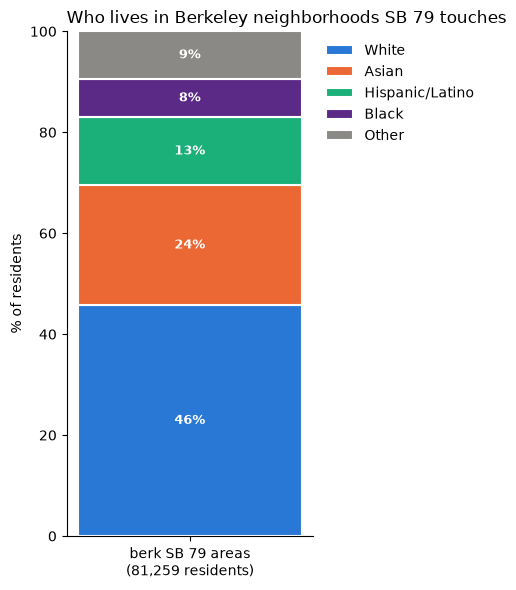

,White,Asian,Hispanic/Latino,Black,Other
"berk SB 79 areas\n(81,259 residents)",45.7,23.8,13.4,7.6,9.4


In [24]:
all_row = bg[race_groups].sum() / bg["pop_total"].sum() * 100
all_table = pd.DataFrame([all_row], index=["berk SB 79 areas\n(" + f"{int(bg['pop_total'].sum()):,}" + " residents)"])

fig, ax = plt.subplots(figsize=(5, 6))
stacked_bars(ax, all_table, "Who lives in Berkeley neighborhoods SB 79 touches")
plt.tight_layout()
plt.savefig(vis_dir / "berk_race_breakdown_sb79_areas.png", dpi=150, bbox_inches="tight")
plt.show()
all_table.round(1)

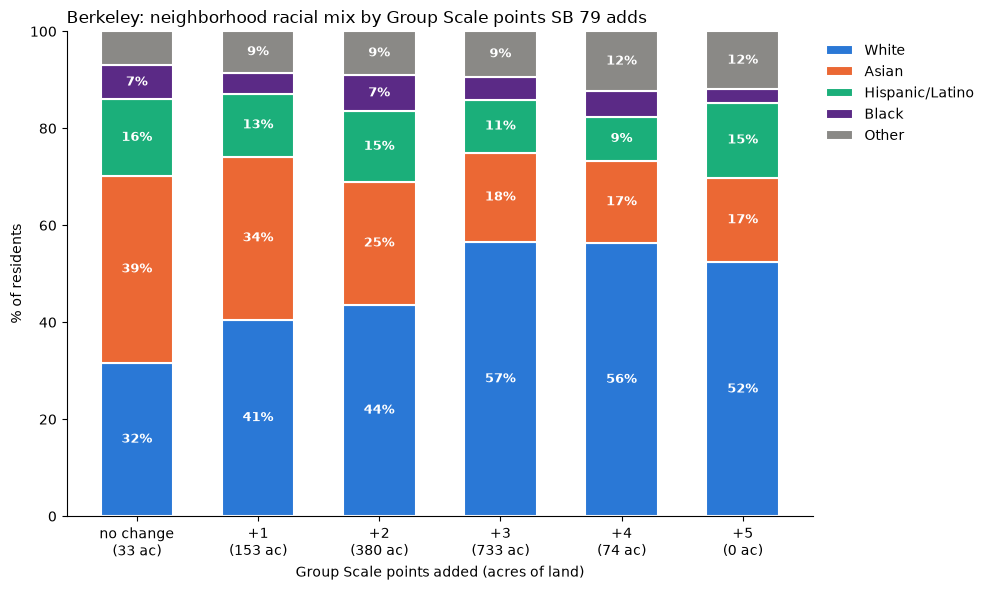

,White,Asian,Hispanic/Latino,Black,Other
no change\n(33 ac),31.7,38.6,15.7,7.1,7.0
+1\n(153 ac),40.6,33.6,13.0,4.3,8.5
+2\n(380 ac),43.6,25.3,14.6,7.5,9.0
+3\n(733 ac),56.6,18.4,10.8,4.8,9.4
+4\n(74 ac),56.3,16.9,9.2,5.2,12.4
+5\n(0 ac),52.3,17.5,15.5,2.7,12.0


In [25]:
g = berk[berk["pop_total"] > 0].dropna(subset=["net_scale_increase"]).copy()
pop_cols = {"White": "pop_nh_white", "Asian": "pop_nh_asian", "Hispanic/Latino": "pop_hispanic",
            "Black": "pop_nh_black", "Other": "pop_other"}
for grp, col in pop_cols.items():
    g[grp] = g[col] / g["pop_total"] * g["acres_geom"]     # share x acres

totals = g.groupby("net_scale_increase")[race_groups + ["acres_geom"]].sum()
pts_table = totals[race_groups].div(totals[race_groups].sum(axis=1), axis=0) * 100

# readable bar names like "+3 (2,341 ac)"
new_names = []
for pts in pts_table.index:
    acres = f"{totals.loc[pts, 'acres_geom']:,.0f}"
    if pts == 0:
        new_names.append("no change\n(" + acres + " ac)")
    else:
        new_names.append("+" + str(int(pts)) + "\n(" + acres + " ac)")
pts_table.index = new_names

fig, ax = plt.subplots(figsize=(10, 6))
stacked_bars(ax, pts_table, "Berkeley: neighborhood racial mix by Group Scale points SB 79 adds")
ax.set_xlabel("Group Scale points added (acres of land)")
plt.tight_layout()
plt.savefig(vis_dir / "berk_race_by_points_added.png", dpi=150, bbox_inches="tight")
plt.show()
pts_table.round(1)

In [26]:
# Consolidate household income into five categories

income_groups = {
    "Under $50k": [
        "hh_inc_under_10k",
        "hh_inc_10k_to_14k",
        "hh_inc_15k_to_19k",
        "hh_inc_20k_to_24k",
        "hh_inc_25k_to_29k",
        "hh_inc_30k_to_34k",
        "hh_inc_35k_to_39k",
        "hh_inc_40k_to_44k",
        "hh_inc_45k_to_49k"
    ],
    "$50k–$99k": [
        "hh_inc_50k_to_59k",
        "hh_inc_60k_to_74k",
        "hh_inc_75k_to_99k"
    ],
    "$100k–$149k": [
        "hh_inc_100k_to_124k",
        "hh_inc_125k_to_149k"
    ],
    "$150k–$199k": [
        "hh_inc_150k_to_199k"
    ],
    "$200k+": [
        "hh_inc_200k_plus"
    ]
}

income_pct_cols = {
    "Under $50k": "pct_income_under_50k",
    "$50k–$99k": "pct_income_50k_99k",
    "$100k–$149k": "pct_income_100k_149k",
    "$150k–$199k": "pct_income_150k_199k",
    "$200k+": "pct_income_200k_plus"
}

# Calculate percentage of households in each category
for group, cols in income_groups.items():
    berk[income_pct_cols[group]] = (
        berk[cols].sum(axis=1, min_count=len(cols))
        / berk["hh_total"].loc[berk["hh_total"] > 0]
        * 100
    )

In [27]:
# Households with at least one vehicle
berk["pct_car_owning"] = 100 - berk["pct_zero_car_all"]

# Combined public transit, walking and cycling
berk["pct_transit_active"] = (
    berk["pct_transit"]
    + berk["pct_bike"]
    + berk["pct_walk"]
)

# Walking and cycling only
berk["pct_active_commute"] = (
    berk["pct_bike"]
    + berk["pct_walk"]
)

# Difference in zero-car rates between renters and owners
berk["zero_car_rent_vs_own"] = (
    berk["pct_zero_car_renter"]
    - berk["pct_zero_car_owner"]
)

In [65]:
def plot_demographic(
    ax,
    col,
    title,
    bins,
    labels,
    cmap="Blues",
    legend_title=None,
    custom_colors=None
):
    # Assign each parcel to a category
    categories = pd.cut(
        berk[col],
        bins=bins,
        labels=labels,
        include_lowest=True
    )

    # Generate colors for the categories
    if custom_colors is None:
        color_map = plt.get_cmap(cmap)

        map_colors = [
            color_map(0.25 + 0.7 * i / max(len(labels) - 1, 1))
            for i in range(len(labels))
        ]
    else:
        map_colors = custom_colors

    # Plot each category separately
    for label, color in zip(labels, map_colors):
        layer = berk[categories == label]

        if len(layer) > 0:
            layer.plot(
                ax=ax,
                color=color,
                linewidth=0
            )

    # Plot parcels with missing data
    missing = berk[categories.isna()]

    if len(missing) > 0:
        missing.plot(
            ax=ax,
            color=no_data_color,
            linewidth=0
        )

    # Keep map extent consistent across panels
    xmin, ymin, xmax, ymax = berk.total_bounds
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    # Add existing basemap
    add_basemap(ax)

    # Create categorical legend
    handles = [
        Patch(color=color, label=label)
        for label, color in zip(labels, map_colors)
    ]

    if len(missing) > 0:
        handles.append(
            Patch(color=no_data_color, label="No data")
        )

    ax.legend(
        handles=handles,
        title=legend_title,
        loc="lower left",
        frameon=False
    )

    ax.set_title(
    title,
    loc="left",
    fontsize=13,
    pad=12
)
    ax.set_axis_off()


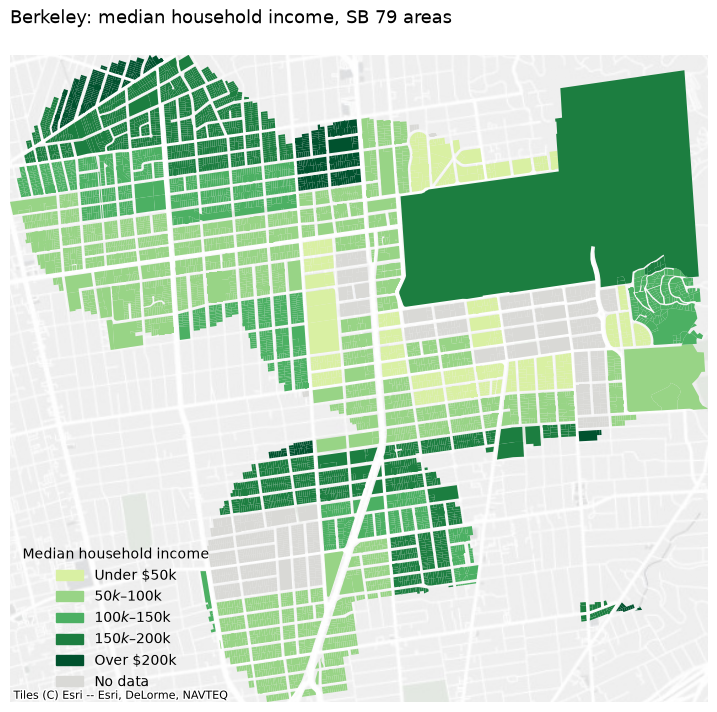

In [66]:
income_bins = [
    0, 50000, 100000, 150000, 200000, float("inf")
]

income_labels = [
    "Under $50k",
    "$50k–$100k",
    "$100k–$150k",
    "$150k–$200k",
    "Over $200k"
]

fig, ax = plt.subplots(figsize=(9, 9))

plot_demographic(
    ax,
    col="median_hh_income",
    title="Berkeley: median household income, SB 79 areas",
    bins=income_bins,
    labels=income_labels,
    cmap="YlGn",
    legend_title="Median household income"
)

plt.savefig(
    vis_dir / "berk_median_income_map.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

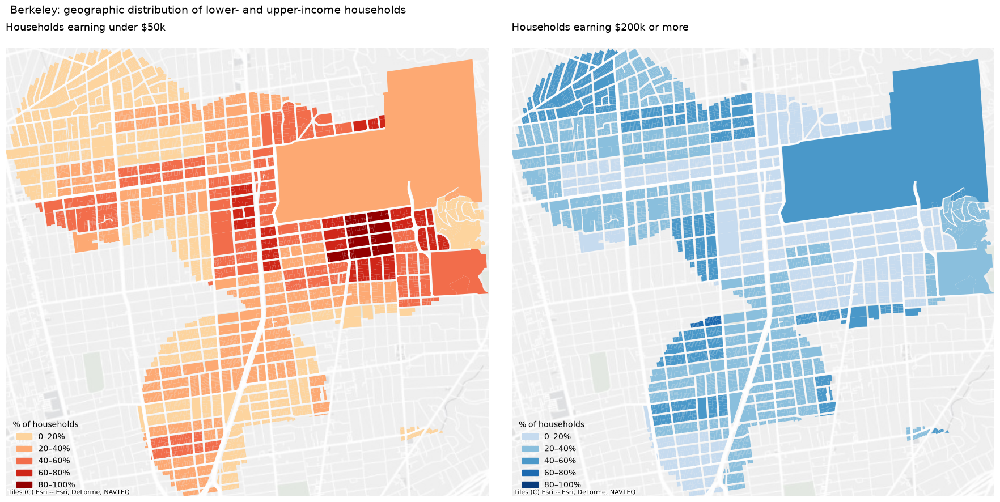

In [67]:
pct_bins = [0, 20, 40, 60, 80, 100]

pct_labels = [
    "0–20%",
    "20–40%",
    "40–60%",
    "60–80%",
    "80–100%"
]

fig, axes = plt.subplots(1, 2, figsize=(18, 9))

# Lower-income households
plot_demographic(
    axes[0],
    col="pct_income_under_50k",
    title="Households earning under $50k",
    bins=pct_bins,
    labels=pct_labels,
    cmap="OrRd",
    legend_title="% of households"
)

# Upper-income households
plot_demographic(
    axes[1],
    col="pct_income_200k_plus",
    title="Households earning $200k or more",
    bins=pct_bins,
    labels=pct_labels,
    cmap="Blues",
    legend_title="% of households"
)

fig.suptitle(
    "Berkeley: geographic distribution of lower- and upper-income households",
    x=0.02,
    ha="left",
    fontsize=14
)

plt.tight_layout(rect=(0, 0, 1, 0.95))

plt.savefig(
    vis_dir / "berk_income_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

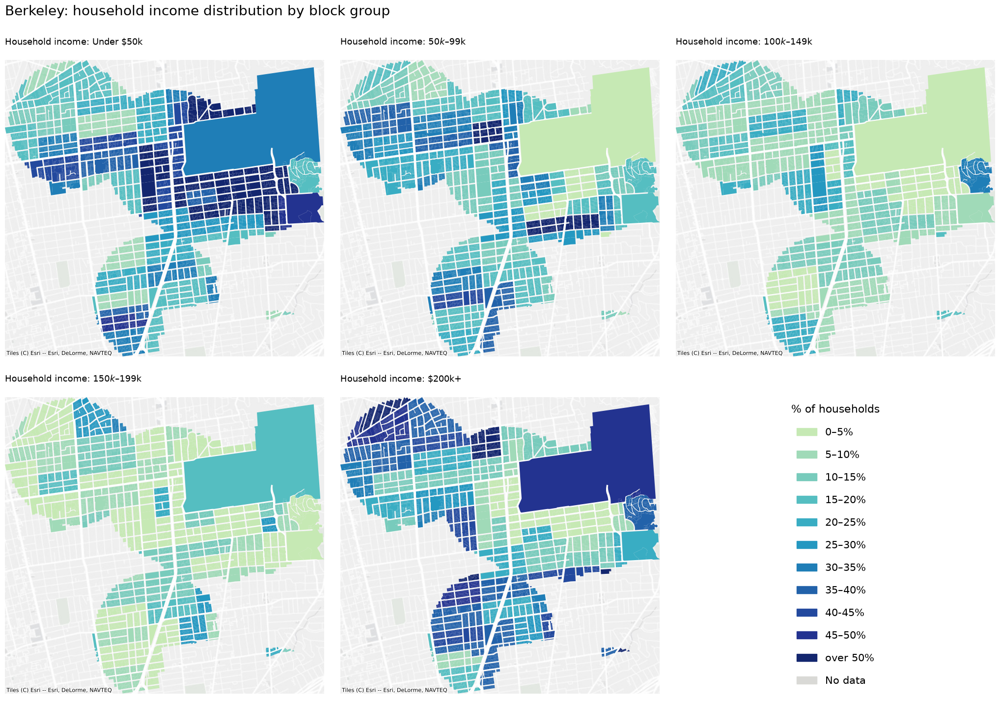

In [111]:
fig, axes = plt.subplots(2, 3, figsize=(21, 15))

income_pct_bins = [
    0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 100
]

income_pct_labels = [
    "0–5%",
    "5–10%",
    "10–15%",
    "15–20%",
    "20–25%",
    "25–30%",
    "30–35%",
    "35–40%",
    "40-45%",
    "45–50%",
    "over 50%"
]

for ax, (group, col) in zip(
    axes.flat,
    income_pct_cols.items()
):
    plot_demographic(
        ax,
        col=col,
        title=f"Household income: {group}",
        bins=income_pct_bins,
        labels=income_pct_labels,
        cmap="YlGnBu",
        legend_title="% of households"
    )

    # Remove the individual map legend
    ax.get_legend().remove()

# Use the empty sixth panel for a shared legend
legend_ax = axes[1, 2]
legend_ax.set_axis_off()

# Recreate the same colors used in plot_demographic()
cmap = plt.get_cmap("YlGnBu")

colors = [
    cmap(0.25 + 0.7 * i / max(len(income_pct_labels) - 1, 1))
    for i in range(len(income_pct_labels))
]

handles = [
    Patch(color=color, label=label)
    for label, color in zip(income_pct_labels, colors)
]

handles.append(
    Patch(color=no_data_color, label="No data")
)

legend_ax.legend(
    handles=handles,
    title="% of households",
    loc="center",
    fontsize=15,
    title_fontsize=16,
    frameon=False,
    labelspacing=1.2
)

# Overall figure title
fig.suptitle(
    "Berkeley: household income distribution by block group",
    x=0.02,
    y=0.97,
    ha="left",
    fontsize=20
)

fig.subplots_adjust(
    left=0.02,
    right=0.98,
    top=0.9,
    bottom=0.03,
    hspace=0.11,
    wspace=0.05
)

plt.savefig(
    vis_dir / "berk_income_categories_map.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

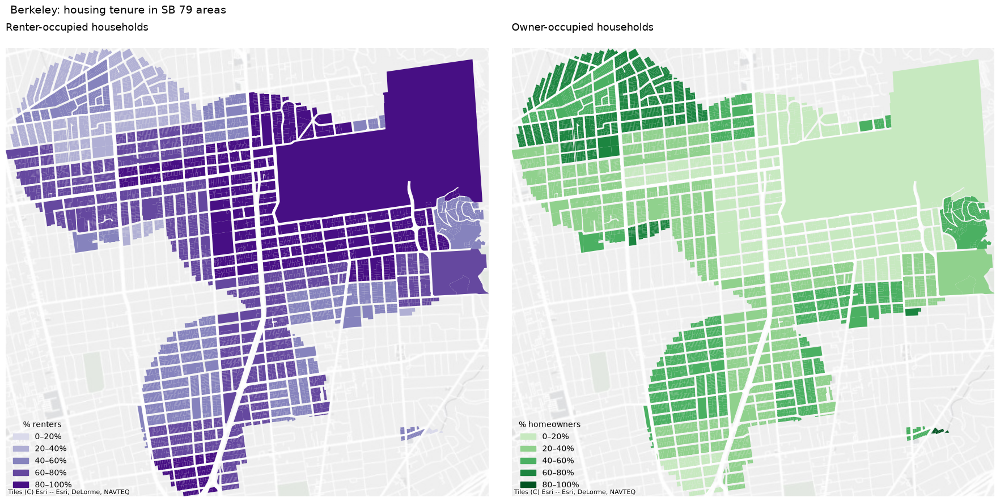

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(18, 9))

plot_demographic(
    axes[0],
    col="pct_renter",
    title="Renter-occupied households",
    bins=pct_bins,
    labels=pct_labels,
    cmap="Purples",
    legend_title="% renters"
)

plot_demographic(
    axes[1],
    col="pct_owner",
    title="Owner-occupied households",
    bins=pct_bins,
    labels=pct_labels,
    cmap="Greens",
    legend_title="% homeowners"
)

fig.suptitle(
    "Berkeley: housing tenure in SB 79 areas",
    x=0.02,
    ha="left",
    fontsize=14
)

plt.tight_layout(rect=(0, 0, 1, 0.95))

plt.savefig(
    vis_dir / "berk_housing_tenure_map.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

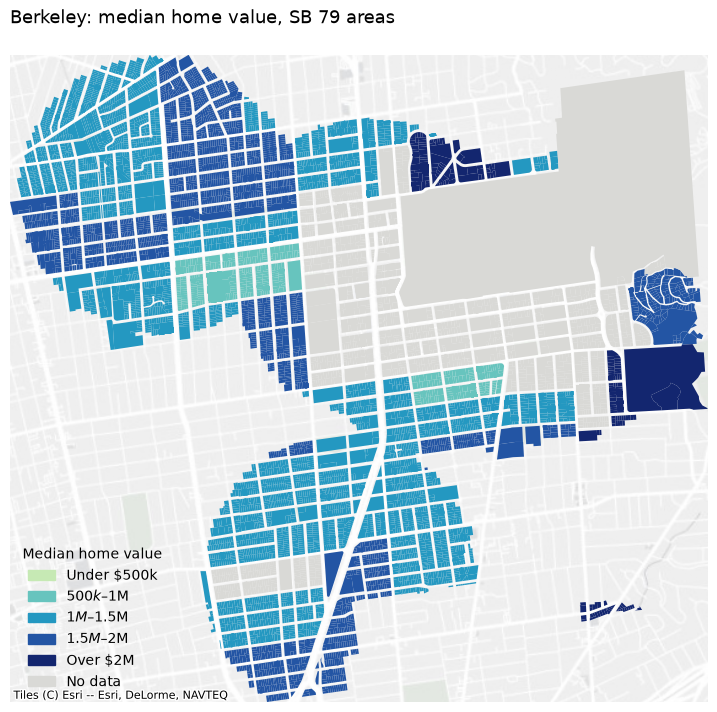

In [70]:
home_value_bins = [
    0,
    500000,
    1000000,
    1500000,
    2000000,
    float("inf")
]

home_value_labels = [
    "Under $500k",
    "$500k–$1M",
    "$1M–$1.5M",
    "$1.5M–$2M",
    "Over $2M"
]

fig, ax = plt.subplots(figsize=(9, 9))

plot_demographic(
    ax,
    col="median_home_value",
    title="Berkeley: median home value, SB 79 areas",
    bins=home_value_bins,
    labels=home_value_labels,
    cmap="YlGnBu",
    legend_title="Median home value"
)

plt.savefig(
    vis_dir / "berk_home_value_map.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

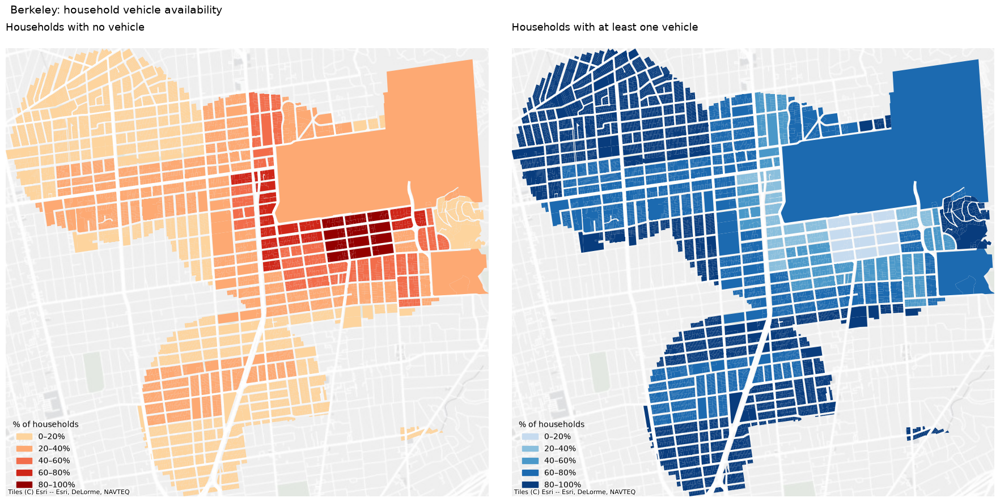

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(18, 9))

plot_demographic(
    axes[0],
    col="pct_zero_car_all",
    title="Households with no vehicle",
    bins=pct_bins,
    labels=pct_labels,
    cmap="OrRd",
    legend_title="% of households"
)

plot_demographic(
    axes[1],
    col="pct_car_owning",
    title="Households with at least one vehicle",
    bins=pct_bins,
    labels=pct_labels,
    cmap="Blues",
    legend_title="% of households"
)

fig.suptitle(
    "Berkeley: household vehicle availability",
    x=0.02,
    ha="left",
    fontsize=14
)

plt.tight_layout(rect=(0, 0, 1, 0.95))

plt.savefig(
    vis_dir / "berk_vehicle_ownership_map.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

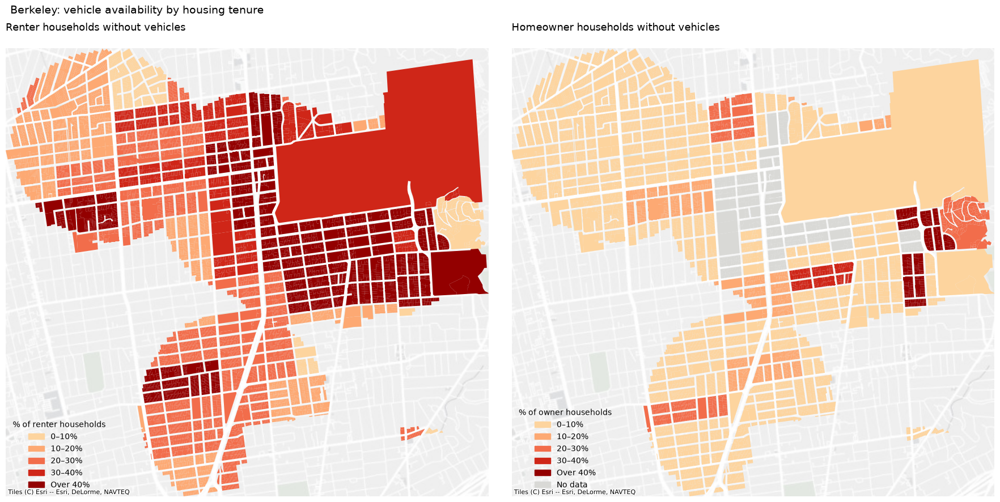

In [72]:
zero_car_bins = [0, 10, 20, 30, 40, 100]

zero_car_labels = [
    "0–10%",
    "10–20%",
    "20–30%",
    "30–40%",
    "Over 40%"
]

fig, axes = plt.subplots(1, 2, figsize=(18, 9))

# Zero-car renter households
plot_demographic(
    axes[0],
    col="pct_zero_car_renter",
    title="Renter households without vehicles",
    bins=zero_car_bins,
    labels=zero_car_labels,
    cmap="OrRd",
    legend_title="% of renter households"
)

# Zero-car homeowner households
plot_demographic(
    axes[1],
    col="pct_zero_car_owner",
    title="Homeowner households without vehicles",
    bins=zero_car_bins,
    labels=zero_car_labels,
    cmap="OrRd",
    legend_title="% of owner households"
)

fig.suptitle(
    "Berkeley: vehicle availability by housing tenure",
    x=0.02,
    ha="left",
    fontsize=14
)

plt.tight_layout(rect=(0, 0, 1, 0.95))

plt.savefig(
    vis_dir / "berk_zero_car_by_tenure.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

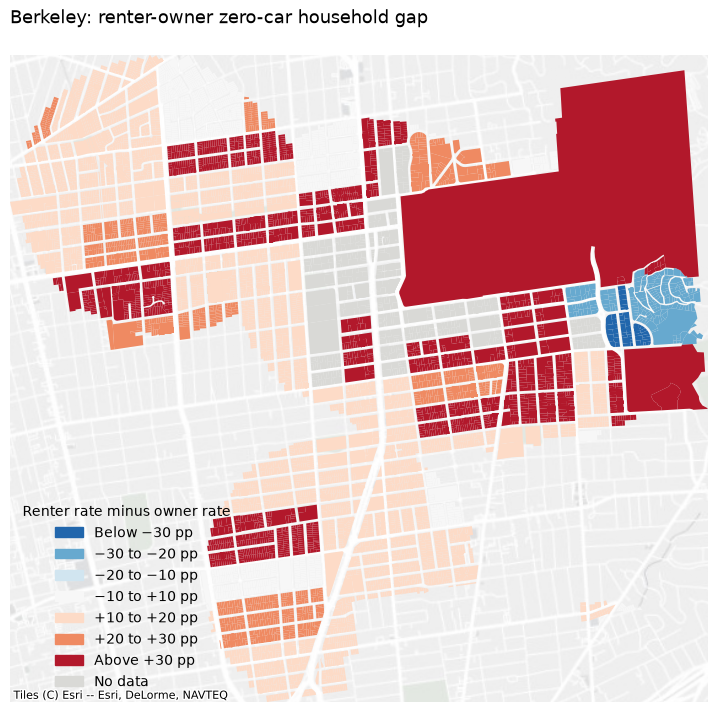

In [114]:
berk["zero_car_gap"] = (
    berk["pct_zero_car_renter"]
    - berk["pct_zero_car_owner"]
)

gap_bins = [
    -100, -30, -20, -10, 10, 20, 30, 100
]

gap_labels = [
    "Below −30 pp",
    "−30 to −20 pp",
    "−20 to −10 pp",
    "−10 to +10 pp",
    "+10 to +20 pp",
    "+20 to +30 pp",
    "Above +30 pp"
]

gap_colors = [
    "#2166ac",
    "#67a9cf",
    "#d1e5f0",
    "#f7f7f7",
    "#fddbc7",
    "#ef8a62",
    "#b2182b"
]

fig, ax = plt.subplots(figsize=(9, 9))

plot_demographic(
    ax,
    col="zero_car_gap",
    title="Berkeley: renter-owner zero-car household gap",
    bins=gap_bins,
    labels=gap_labels,
    custom_colors=gap_colors,
    legend_title="Renter rate minus owner rate"
)

plt.savefig(
    vis_dir / "berk_zero_car_gap_map.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

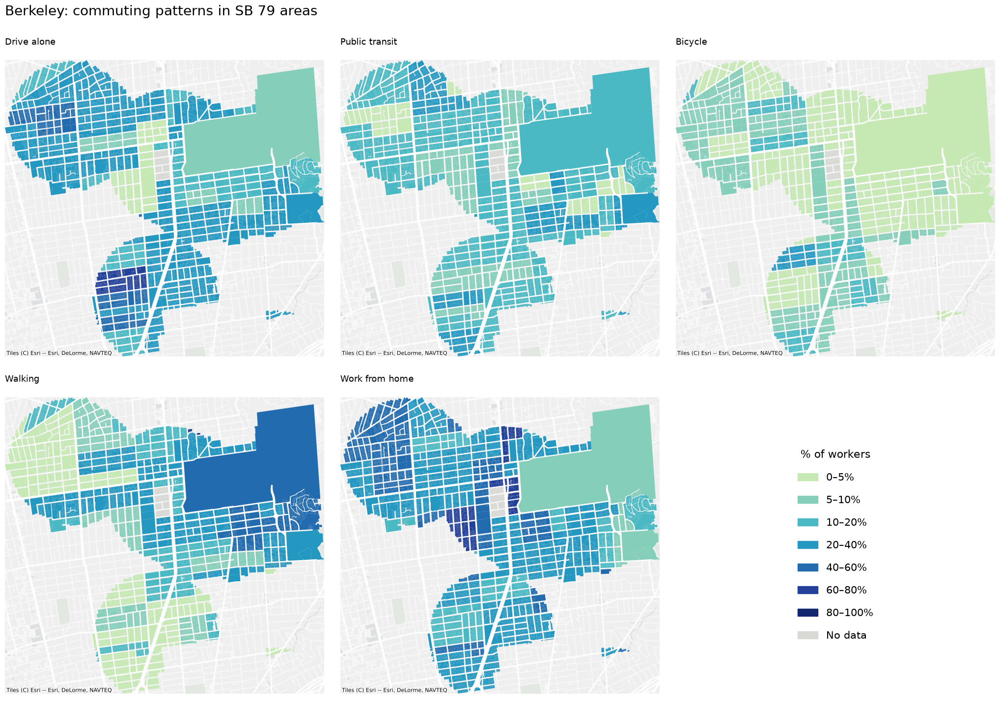

In [118]:
fig, axes = plt.subplots(2, 3, figsize=(21, 15))

commute_bins = [0, 5, 10, 20, 40, 60, 80, 100]

commute_labels = [
    "0–5%",
    "5–10%",
    "10–20%",
    "20–40%",
    "40–60%",
    "60–80%",
    "80–100%"
]

commute_modes = [
    ("pct_drive_alone", "Drive alone"),
    ("pct_transit", "Public transit"),
    ("pct_bike", "Bicycle"),
    ("pct_walk", "Walking"),
    ("pct_wfh", "Work from home")
]


for ax, (col, title) in zip(
    axes.flat,
    commute_modes
):
    plot_demographic(
        ax,
        col=col,
        title=title,
        bins=commute_bins,
        labels=commute_labels,
        cmap="YlGnBu",
        legend_title="% of workers"
    )

    # Remove individual legend
    ax.get_legend().remove()

# Create shared legend in sixth panel
legend_ax = axes[1, 2]
legend_ax.set_axis_off()

cmap = plt.get_cmap("YlGnBu")

colors = [
    cmap(0.25 + 0.7 * i / max(len(commute_labels) - 1, 1))
    for i in range(len(commute_labels))
]

handles = [
    Patch(color=color, label=label)
    for label, color in zip(commute_labels, colors)
]

handles.append(
    Patch(color=no_data_color, label="No data")
)

legend_ax.legend(
    handles=handles,
    title="% of workers",
    loc="center",
    fontsize=15,
    title_fontsize=16,
    frameon=False,
    labelspacing=1.2
)

fig.suptitle(
    "Berkeley: commuting patterns in SB 79 areas",
    x=0.02,
    y=0.97,
    ha="left",
    fontsize=20
)

fig.subplots_adjust(
    left=0.02,
    right=0.98,
    top=0.9,
    bottom=0.03,
    hspace=0.11,
    wspace=0.05
)

plt.savefig(
    vis_dir / "berk_commute_modes_map.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

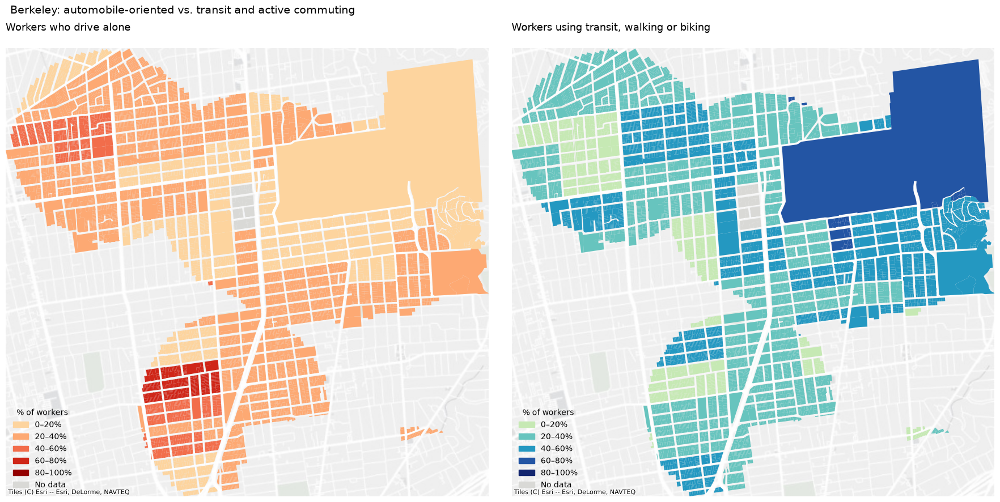

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(18, 9))

plot_demographic(
    axes[0],
    col="pct_drive_alone",
    title="Workers who drive alone",
    bins=pct_bins,
    labels=pct_labels,
    cmap="OrRd",
    legend_title="% of workers"
)

plot_demographic(
    axes[1],
    col="pct_transit_active",
    title="Workers using transit, walking or biking",
    bins=pct_bins,
    labels=pct_labels,
    cmap="YlGnBu",
    legend_title="% of workers"
)

fig.suptitle(
    "Berkeley: automobile-oriented vs. transit and active commuting",
    x=0.02,
    ha="left",
    fontsize=14
)

plt.tight_layout(rect=(0, 0, 1, 0.95))

plt.savefig(
    vis_dir / "berk_commute_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [76]:
def plot_scale_increase(ax):
    handles = []

    for pts, color in SCALE_COLORS.items():
        layer = berk[berk["net_scale_increase"] == pts]

        if len(layer) > 0:
            layer.plot(
                ax=ax,
                color=color,
                linewidth=0
            )

            if pts == 0:
                label = "No change"
            else:
                label = f"+{pts}"

            handles.append(
                Patch(color=color, label=label)
            )

    xmin, ymin, xmax, ymax = berk.total_bounds

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    add_basemap(ax)

    ax.legend(
        handles=handles,
        title="Points added",
        loc="lower left",
        frameon=False
    )

    ax.set_title(
        "Group Scale points SB 79 adds",
        loc="left"
    )

    ax.set_axis_off()

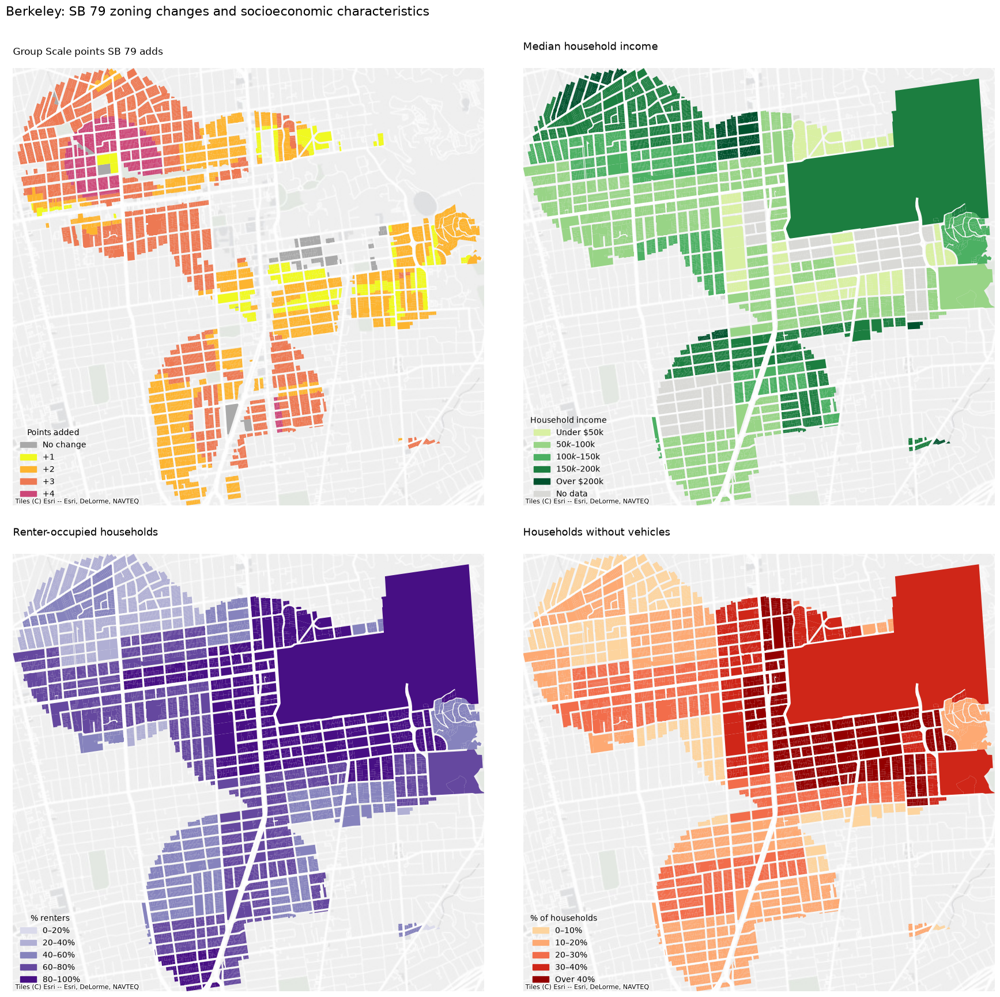

In [117]:
fig, axes = plt.subplots(2, 2, figsize=(18, 18))

# Group Scale increase
plot_scale_increase(axes[0, 0])

# Household income
plot_demographic(
    axes[0, 1],
    col="median_hh_income",
    title="Median household income",
    bins=income_bins,
    labels=income_labels,
    cmap="YlGn",
    legend_title="Household income"
)

# Renter households
plot_demographic(
    axes[1, 0],
    col="pct_renter",
    title="Renter-occupied households",
    bins=pct_bins,
    labels=pct_labels,
    cmap="Purples",
    legend_title="% renters"
)

# Zero-car households
plot_demographic(
    axes[1, 1],
    col="pct_zero_car_all",
    title="Households without vehicles",
    bins=zero_car_bins,
    labels=zero_car_labels,
    cmap="OrRd",
    legend_title="% of households"
)

fig.suptitle(
    "Berkeley: SB 79 zoning changes and socioeconomic characteristics",
    x=0.02,
    ha="left",
    fontsize=16
)

fig.subplots_adjust(
    left=0.02,
    right=0.98,
    top=0.92,
    bottom=0.03,
    hspace=0.11,
    wspace=0.05
)

plt.savefig(
    vis_dir / "berk_scale_vs_socioeconomic_maps.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [78]:
def weighted_by_scale(cols):
    results = {}

    for col in cols:

        # Keep only parcels with valid data
        g = berk.dropna(
            subset=[
                col,
                "acres_geom",
                "net_scale_increase"
            ]
        ).copy()

        g = g[g["acres_geom"] > 0]

        # Multiply demographic variable by parcel acreage
        g["weighted_value"] = (
            g[col] * g["acres_geom"]
        )

        # Sum weighted values and acres by scale increase
        totals = g.groupby("net_scale_increase")[
            ["weighted_value", "acres_geom"]
        ].sum()

        # Divide by total acreage
        results[col] = (
            totals["weighted_value"]
            / totals["acres_geom"]
        )

    return pd.DataFrame(results).sort_index()

In [79]:
summary_cols = [
    "pct_income_under_50k",
    "pct_income_200k_plus",
    "median_hh_income",
    "median_home_value",
    "pct_renter",
    "pct_zero_car_all",
    "pct_zero_car_renter",
    "pct_zero_car_owner",
    "pct_drive_alone",
    "pct_transit",
    "pct_bike",
    "pct_walk",
    "pct_wfh",
    "pct_transit_active"
]

demographic_summary = weighted_by_scale(summary_cols)

demographic_summary.round(1)

,pct_income_under_50k,pct_income_200k_plus,median_hh_income,median_home_value,pct_renter,pct_zero_car_all,pct_zero_car_renter,pct_zero_car_owner,pct_drive_alone,pct_transit,pct_bike,pct_walk,pct_wfh,pct_transit_active
net_scale_increase,,,,,,,,,,,,,,
0.0,46.1,15.0,73443.6,1418689.8,83.3,57.9,60.5,3.1,20.2,9.7,2.8,20.3,38.0,32.9
1.0,45.7,15.8,60934.2,1239651.0,75.3,40.9,45.8,20.3,25.2,16.0,1.5,22.5,30.3,39.9
2.0,32.6,24.5,103255.9,1314465.5,67.7,27.9,33.5,14.8,28.3,15.6,4.3,17.0,28.9,36.9
3.0,28.2,30.9,101133.7,1138876.1,61.3,17.1,22.9,7.0,25.4,11.6,4.8,16.2,37.6,32.6
4.0,17.6,31.9,120410.2,1405179.9,46.0,11.2,20.7,2.3,33.3,10.9,7.4,7.0,37.9,25.2
5.0,9.7,24.8,126406.0,1612200.0,61.4,15.8,20.6,8.1,21.1,11.5,7.3,21.5,31.7,40.4


What does this mean (referring to above): the weighted median household income column is actually an acreage-weighted average of block-group medians, not the overall median income of households in each zoning category.

In [80]:
# Use a common set of parcels with complete income data
income_cols = list(income_pct_cols.values())

g_income = berk.dropna(
    subset=income_cols + [
        "net_scale_increase",
        "acres_geom"
    ]
).copy()

g_income = g_income[g_income["acres_geom"] > 0]

# Weight each income percentage by acreage
for group, col in income_pct_cols.items():
    g_income[group] = (
        g_income[col] * g_income["acres_geom"]
    )

# Aggregate by Group Scale increase
income_totals = g_income.groupby(
    "net_scale_increase"
)[list(income_groups) + ["acres_geom"]].sum()

# Convert weighted totals into percentages
income_table = income_totals[
    list(income_groups)
].div(
    income_totals["acres_geom"],
    axis=0
)

income_table.round(1)

,Under $50k,$50k–$99k,$100k–$149k,$150k–$199k,$200k+
net_scale_increase,,,,,
0.0,46.1,27.7,5.0,6.3,15.0
1.0,45.7,21.2,11.4,5.9,15.8
2.0,32.6,24.9,11.9,6.1,24.5
3.0,28.2,21.6,9.9,9.3,30.9
4.0,17.6,26.9,12.6,11.0,31.9
5.0,9.7,30.2,21.5,13.8,24.8


In [123]:
def plot_stacked_composition(
    ax,
    table,
    group_colors,
    title,
    ylabel="% of households"
):
    bottom = pd.Series(
        0.0,
        index=table.index
    )

    for group in table.columns:

        ax.bar(
            table.index,
            table[group],
            bottom=bottom,
            color=group_colors[group],
            label=group,
            edgecolor="white",
            linewidth=1.5,
            width=0.6
        )

        # Label sufficiently large segments
        for i, bar_name in enumerate(table.index):
            value = table.loc[bar_name, group]

            if value >= 7:
                ax.text(
                    i,
                    bottom[bar_name] + value / 2,
                    f"{value:.0f}%",
                    ha="center",
                    va="center",
                    color="white",
                    fontsize=10,
                    fontweight="bold"
                )

        bottom = bottom + table[group]

    ax.set_ylim(0, 100)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1, 1),
        frameon=False
    )

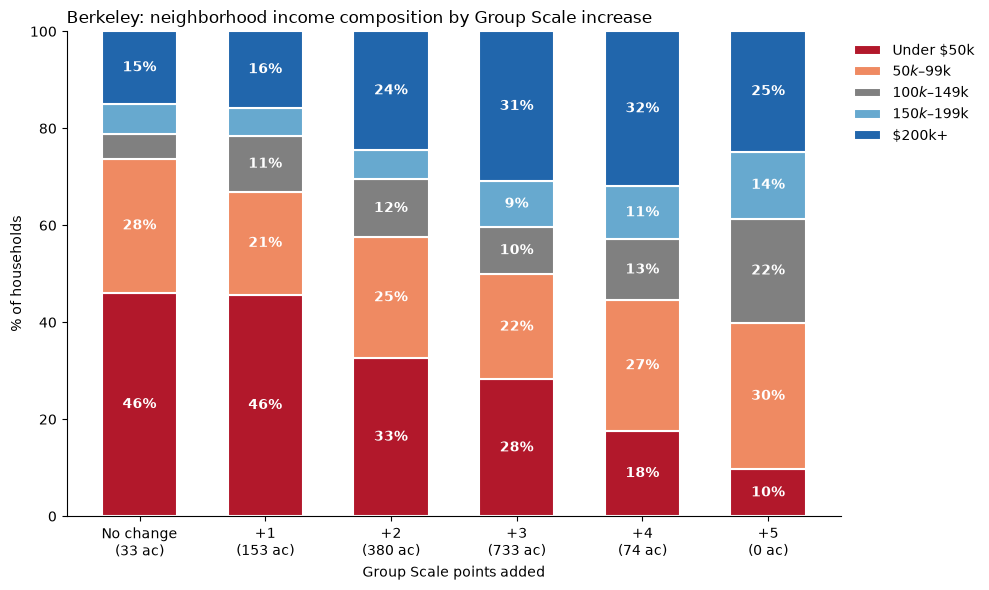

In [126]:
income_colors = {
    "Under $50k": "#b2182b",
    "$50k–$99k": "#ef8a62",
    "$100k–$149k": "#808080",
    "$150k–$199k": "#67a9cf",
    "$200k+": "#2166ac"
}

# Create readable labels
income_plot_table = income_table.copy()

income_plot_table.index = [
    (
        "No change" if pts == 0
        else f"+{int(pts)}"
    )
    + f"\n({income_totals.loc[pts, 'acres_geom']:,.0f} ac)"
    for pts in income_table.index
]

fig, ax = plt.subplots(figsize=(10, 6))

plot_stacked_composition(
    ax,
    income_plot_table,
    income_colors,
    "Berkeley: neighborhood income composition by Group Scale increase"
)

ax.set_xlabel("Group Scale points added")

plt.tight_layout()

plt.savefig(
    vis_dir / "berk_income_by_points_added.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

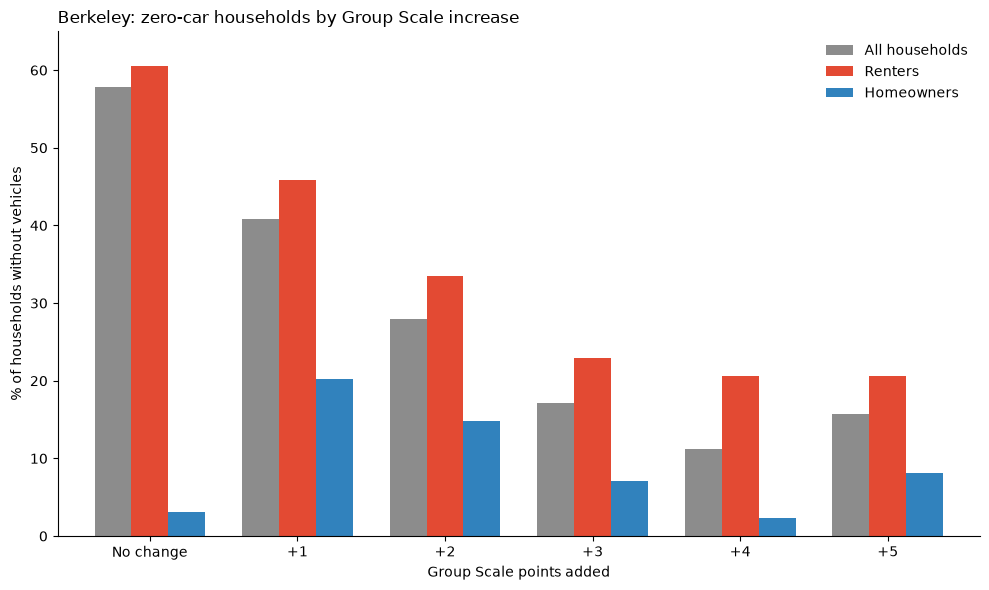

In [136]:
vehicle_table = weighted_by_scale([
    "pct_zero_car_all",
    "pct_zero_car_renter",
    "pct_zero_car_owner"
])

vehicle_table = vehicle_table.rename(columns={
    "pct_zero_car_all": "All households",
    "pct_zero_car_renter": "Renters",
    "pct_zero_car_owner": "Homeowners"
})

vehicle_table.index = [
    "No change" if pts == 0 else f"+{int(pts)}"
    for pts in vehicle_table.index
]

fig, ax = plt.subplots(figsize=(10, 6))

vehicle_table.plot(
    kind="bar",
    ax=ax,
    color=["#8c8c8c", "#e34a33", "#3182bd"],
    width=0.75
)

ax.set_title(
    "Berkeley: zero-car households by Group Scale increase",
    loc="left"
)

ax.set_ylabel("% of households without vehicles")
ax.set_xlabel("Group Scale points added")
ax.set_ylim(0, 65)

ax.tick_params(axis="x", rotation=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False)

plt.tight_layout()

plt.savefig(
    vis_dir / "berk_zero_car_by_points_added.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [84]:
commute_cols = {
    "Drive alone": "pct_drive_alone",
    "Public transit": "pct_transit",
    "Bicycle": "pct_bike",
    "Walking": "pct_walk",
    "Work from home": "pct_wfh"
}

# Capture unlisted modes such as carpooling
berk["pct_other_commute"] = (
    100 - berk[list(commute_cols.values())].sum(
        axis=1,
        min_count=len(commute_cols)
    )
)

# Allow for tiny floating-point rounding differences
berk["pct_other_commute"] = (
    berk["pct_other_commute"]
    .where(berk["pct_other_commute"] >= -0.01)
    .clip(lower=0)
)

commute_cols["Other"] = "pct_other_commute"

# Keep parcels with complete commuting data
g_commute = berk.dropna(
    subset=list(commute_cols.values()) + [
        "net_scale_increase",
        "acres_geom"
    ]
).copy()

g_commute = g_commute[g_commute["acres_geom"] > 0]

# Multiply percentage by parcel acreage
for mode, col in commute_cols.items():
    g_commute[mode] = (
        g_commute[col] * g_commute["acres_geom"]
    )

# Group by scale increase
commute_totals = g_commute.groupby(
    "net_scale_increase"
)[list(commute_cols) + ["acres_geom"]].sum()

commute_table = commute_totals[
    list(commute_cols)
].div(
    commute_totals["acres_geom"],
    axis=0
)

commute_table.round(1)

,Drive alone,Public transit,Bicycle,Walking,Work from home,Other
net_scale_increase,,,,,,
0.0,20.2,9.7,2.8,20.3,38.0,8.8
1.0,25.2,16.0,1.5,22.5,30.3,4.6
2.0,28.3,15.6,4.3,17.0,28.9,5.9
3.0,25.4,11.6,4.8,16.2,37.6,4.4
4.0,33.3,10.9,7.4,7.0,37.9,3.5
5.0,21.1,11.5,7.3,21.5,31.7,6.9


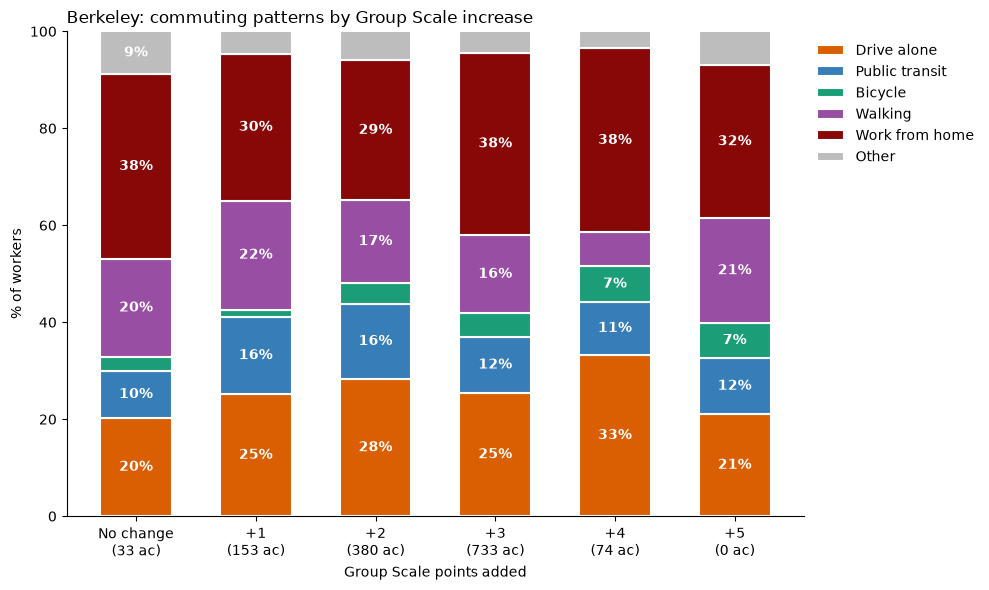

In [134]:
commute_colors = {
    "Drive alone": "#d95f02",
    "Public transit": "#377eb8",
    "Bicycle": "#1b9e77",
    "Walking": "#984ea3",
    "Work from home": "#880808",
    "Other": "#bdbdbd"
}

commute_plot_table = commute_table.copy()

commute_plot_table.index = [
    (
        "No change" if pts == 0
        else f"+{int(pts)}"
    )
    + f"\n({commute_totals.loc[pts, 'acres_geom']:,.0f} ac)"
    for pts in commute_table.index
]

fig, ax = plt.subplots(figsize=(10, 6))

plot_stacked_composition(
    ax,
    commute_plot_table,
    commute_colors,
    "Berkeley: commuting patterns by Group Scale increase",
    ylabel="% of workers"
)

ax.set_xlabel("Group Scale points added")

plt.tight_layout()

plt.savefig(
    vis_dir / "berk_commute_by_points_added.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [86]:
berk["upzoning_category"] = pd.cut(
    berk["net_scale_increase"],
    bins=[-0.5, 0.5, 2.5, 4.5],
    labels=[
        "No increase",
        "Moderate increase (1–2)",
        "Large increase (3–4)"
    ]
)

comparison_cols = {
    "pct_income_under_50k": "Households under $50k",
    "pct_income_200k_plus": "Households $200k+",
    "pct_renter": "Renter households",
    "pct_zero_car_all": "Zero-car households",
    "pct_drive_alone": "Drive-alone commuters",
    "pct_transit_active": "Transit and active commuters"
}

comparison = {}

for col, label in comparison_cols.items():

    g = berk.dropna(
        subset=[
            col,
            "upzoning_category",
            "acres_geom"
        ]
    ).copy()

    g = g[g["acres_geom"] > 0]

    g["weighted_value"] = (
        g[col] * g["acres_geom"]
    )

    totals = g.groupby(
        "upzoning_category",
        observed=True
    )[["weighted_value", "acres_geom"]].sum()

    comparison[label] = (
        totals["weighted_value"]
        / totals["acres_geom"]
    )

comparison_table = pd.DataFrame(comparison).T

comparison_table.round(1)

upzoning_category,No increase,Moderate increase (1–2),Large increase (3–4)
Households under $50k,46.1,36.4,27.2
Households $200k+,15.0,22.0,31.0
Renter households,83.3,69.9,59.9
Zero-car households,57.9,31.6,16.5
Drive-alone commuters,20.2,27.4,26.1
Transit and active commuters,32.9,37.8,31.9


In [ ]:
comparison_table["Difference (pp)"] = (
    comparison_table["Large increase (3–4)"]
    - comparison_table["No increase"]
)

comparison_table.round(1)

upzoning_category,No increase,Moderate increase (1–2),Large increase (3–4),Difference (pp)
Households under $50k,46.1,36.4,27.2,-18.8
Households $200k+,15.0,22.0,31.0,16.0
Renter households,83.3,69.9,59.9,-23.4
Zero-car households,57.9,31.6,16.5,-41.3
Drive-alone commuters,20.2,27.4,26.1,5.9
Transit and active commuters,32.9,37.8,31.9,-1.0


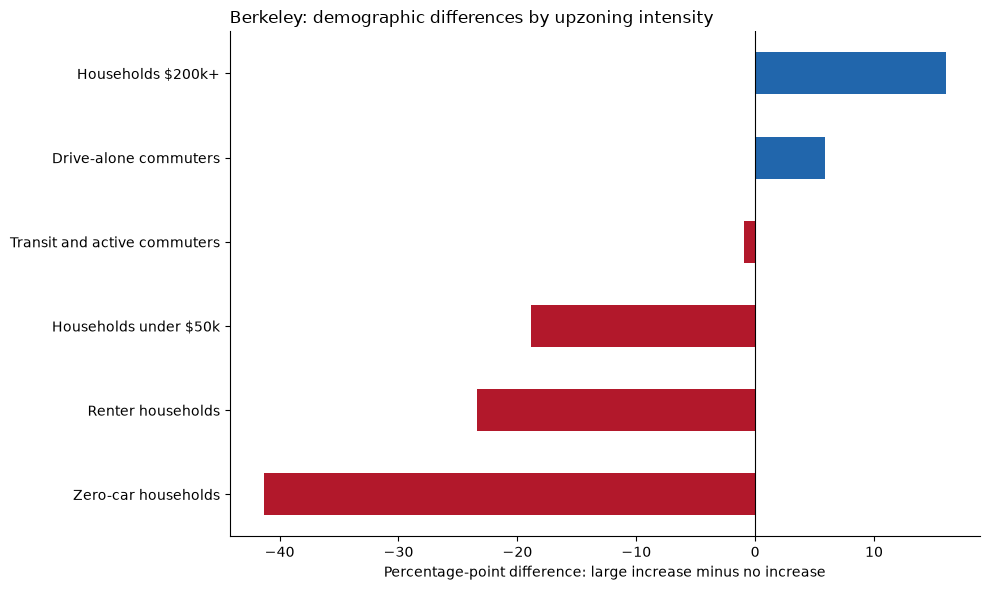

In [88]:
difference = comparison_table[
    "Difference (pp)"
].dropna().sort_values()

bar_colors = [
    "#b2182b" if value < 0 else "#2166ac"
    for value in difference
]

fig, ax = plt.subplots(figsize=(10, 6))

difference.plot(
    kind="barh",
    ax=ax,
    color=bar_colors
)

ax.axvline(
    0,
    color="black",
    linewidth=0.8
)

ax.set_xlabel(
    "Percentage-point difference: large increase minus no increase"
)

ax.set_title(
    "Berkeley: demographic differences by upzoning intensity",
    loc="left"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    vis_dir / "berk_demographic_disparities.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

^Chat explanation: Red bars indicate demographic characteristics that are less prevalent in neighborhoods receiving large zoning increases. Blue bars indicate characteristics that are more prevalent.